# ONNX 처리율 (실녹음 전처리)

`data/psj`, `data/jsh`의 wav를 `features.py`로 uint8 `[3, 64, 64]`로 만든 뒤, 그 창을 ONNX에 넣습니다. `calib_100.npy`는 쓰지 않습니다. 창 자르기는 `bench_fps.ipynb`의 C++ 측정과 같습니다.

- 1.5초 이하 클립은 가운데 1초, 더 긴 speech는 겹치지 않는 1초입니다.
- 전처리 시간은 `features()`만 잽니다.
- ONNX 시간은 이미 만든 배치에서 `sess.run` 한 장씩만 잽니다. 입력은 float32 `[1, 3, 64, 64]`, 값 0~255입니다.
- 처리율은 창 개수 / 걸린 시간입니다.


In [1]:
%matplotlib inline
import json, os, sys, time, wave
from pathlib import Path

import numpy as np
import onnxruntime as ort
import matplotlib.pyplot as plt

os.environ.setdefault("ORT_DISABLE_TELEMETRY", "1")

ROOT = Path.cwd().resolve()
while not (ROOT / "features.py").is_file():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("features.py를 찾지 못했습니다")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import features as F

CLASSES = ["whistle_up", "whistle_down", "tongue_click2", "shh", "clap2", "speech", "background"]
SETS = [ROOT / "data" / "psj", ROOT / "data" / "jsh"]
MODELS = [
    ROOT / "models" / "resnet18_v1" / "resnet18_v1.onnx",
    ROOT / "models" / "mobilenet_v2_v1" / "mobilenet_v2_v1.onnx",
]
OUT = ROOT / "models" / "onnx_fps"
OUT.mkdir(parents=True, exist_ok=True)
SR, N = 16000, 16000

def load_wav(path):
    with wave.open(str(path)) as w:
        return np.frombuffer(w.readframes(w.getnframes()), dtype=np.int16).copy()

def windows_of(x):
    if len(x) <= N + SR // 2:
        return [F.fit_length(x)]
    n = len(x) // N
    return [x[i * N:(i + 1) * N].astype(np.float32) / 32768.0 for i in range(n)]

def clips_of(folder):
    clips = []
    for name in CLASSES:
        d = folder / name
        if not d.is_dir():
            continue
        for path in sorted(d.glob("*.wav")):
            clips.extend(windows_of(load_wav(path)))
    if not clips:
        raise FileNotFoundError(f"wav 창이 없습니다: {folder}")
    return clips

def preprocess(clips):
    F.features(clips[0])
    t0 = time.perf_counter()
    imgs = [F.features(clip) for clip in clips]
    dt = time.perf_counter() - t0
    batch = np.stack(imgs).astype(np.float32)
    return batch, dt

print("ort", ort.__version__, "cpu", os.cpu_count())
print("sets", [str(p) for p in SETS])


ort 1.32.0 cpu 4
sets ['/home/kau-2024128055/kau-on-device-final/data/psj', '/home/kau-2024128055/kau-on-device-final/data/jsh']


In [2]:
def bench_onnx(path, batch):
    so = ort.SessionOptions()
    so.graph_optimization_level = ort.GraphOptimizationLevel.ORT_ENABLE_ALL
    sess = ort.InferenceSession(str(path), so, providers=["CPUExecutionProvider"])
    name = sess.get_inputs()[0].name
    sess.run(None, {name: batch[:1]})
    t0 = time.perf_counter()
    for i in range(len(batch)):
        sess.run(None, {name: batch[i:i + 1]})
    dt = time.perf_counter() - t0
    n = len(batch)
    return {
        "model": path.name,
        "windows": n,
        "onnx_s": round(dt, 6),
        "onnx_ms": round(1000.0 * dt / n, 3),
        "onnx_fps": round(n / dt, 1),
    }

rows = []
for folder in SETS:
    clips = clips_of(folder)
    batch, prep_s = preprocess(clips)
    n = len(batch)
    base = {
        "set": folder.name,
        "windows": n,
        "preprocess_s": round(prep_s, 6),
        "preprocess_ms": round(1000.0 * prep_s / n, 3),
        "preprocess_fps": round(n / prep_s, 1),
    }
    for path in MODELS:
        row = dict(base)
        row.update(bench_onnx(path, batch))
        row["windows"] = n
        rows.append(row)
        print(
            f"{row['set']:<4} {row['model']:<22} 창 {n:4d}  "
            f"전처리 {row['preprocess_fps']:7.1f} FPS ({row['preprocess_ms']:.2f} ms)  "
            f"ONNX {row['onnx_fps']:7.1f} FPS ({row['onnx_ms']:.2f} ms)"
        )

report = {
    "runtime": "onnxruntime",
    "ort_version": ort.__version__,
    "provider": "CPUExecutionProvider",
    "input": "features.py uint8 -> float32 [1,3,64,64]",
    "sets": [str(p) for p in SETS],
    "rows": rows,
}
json_path = OUT / "fps.json"
json_path.write_text(json.dumps(report, indent=2) + "\n")
print("saved", json_path)


psj  resnet18_v1.onnx       창  800  전처리   547.6 FPS (1.83 ms)  ONNX    78.8 FPS (12.69 ms)


psj  mobilenet_v2_v1.onnx   창  800  전처리   547.6 FPS (1.83 ms)  ONNX   371.2 FPS (2.69 ms)


jsh  resnet18_v1.onnx       창 2036  전처리  1052.6 FPS (0.95 ms)  ONNX    76.0 FPS (13.17 ms)


jsh  mobilenet_v2_v1.onnx   창 2036  전처리  1052.6 FPS (0.95 ms)  ONNX   339.9 FPS (2.94 ms)
saved /home/kau-2024128055/kau-on-device-final/models/onnx_fps/fps.json


saved /home/kau-2024128055/kau-on-device-final/models/onnx_fps/fps_onnx.png


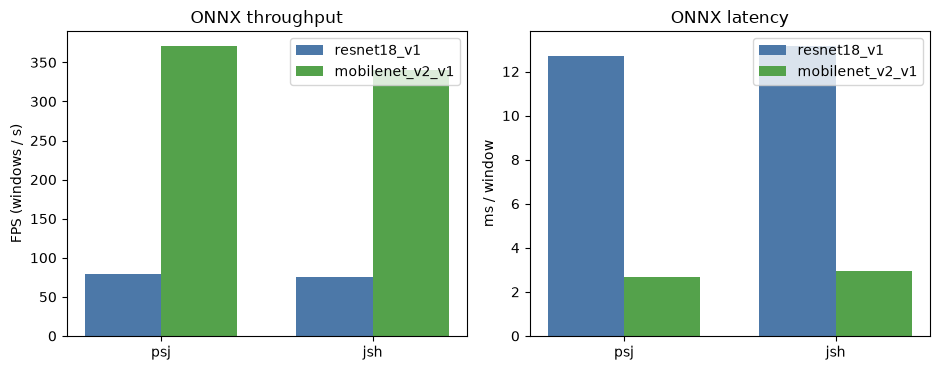

In [3]:
sets = []
for row in rows:
    if row["set"] not in sets:
        sets.append(row["set"])
models = []
for row in rows:
    if row["model"] not in models:
        models.append(row["model"])

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.8))
x = np.arange(len(sets))
w = 0.36
colors = ["#4C78A8", "#54A24B"]
for ax, key, title, ylabel in (
    (axes[0], "onnx_fps", "ONNX throughput", "FPS (windows / s)"),
    (axes[1], "onnx_ms", "ONNX latency", "ms / window"),
):
    for i, model in enumerate(models):
        vals = [next(r[key] for r in rows if r["set"] == s and r["model"] == model) for s in sets]
        ax.bar(x + (i - 0.5) * w, vals, width=w, label=model.replace(".onnx", ""), color=colors[i])
    ax.set_xticks(x, sets)
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.legend()
fig.tight_layout()
fig_path = OUT / "fps_onnx.png"
fig.savefig(fig_path, dpi=120)
print("saved", fig_path)
plt.show()
